## Introduction
This notebook will perform extensive data analysis regarding bird bioacoustic monitoring. The data will be taken from the article "Automated identification of individual birds by song enables multi-year recapture from passive acoustic monitoring data", and it is located under resources/localized_events.csv. 

In [41]:
# First, we must import the necessary packages and libraries
import pandas as pd
import matplotlib as mpl
import numpy as np
from pathlib import Path 
from plotnine import ( 
    ggplot, 
    aes, 
    geom_point,
    geom_bar,
    facet_wrap,
    theme,
    labs,
    scale_fill_manual
)

Then, we will need to load in the data as a dataframe or just fetch the binary if it exists

In [42]:
path = Path("resources/localized_events.parquet")

if path.exists():
    print("Exists, so just load in binary file")
    all_loaded_events_df = pd.read_parquet("resources/localized_events.parquet")
else:
    print("Does not exist, so we create it")
    all_loaded_events_df = pd.read_csv("resources/localized_events.csv")
    all_loaded_events_df.to_parquet("resources/localized_events.parquet")


Exists, so just load in binary file


Now, we will take a subset of the column variables in the data spreadsheet.

In [45]:
subst_loaded_events_df = all_loaded_events_df[
    [
    # Ground truth
    'class',

    # Metadata
    'array',
    'data_split',
    'relative_position',
    'mic_distances_m',

    # Automated models
    'ovenbird_cluster_labels',
    'baseline_resnet18_cluster_labels',
    'hawkears_cluster_labels',
    'birdnet_cluster_labels',
    ]
]

In [49]:
subst_loaded_events_df.to_parquet('resources/subset_loaded_events.parquet')

### Exploratory Data Analysis
We will begin by exploring the distributions of the data to identify possible outliers, trends, and occurrences. 

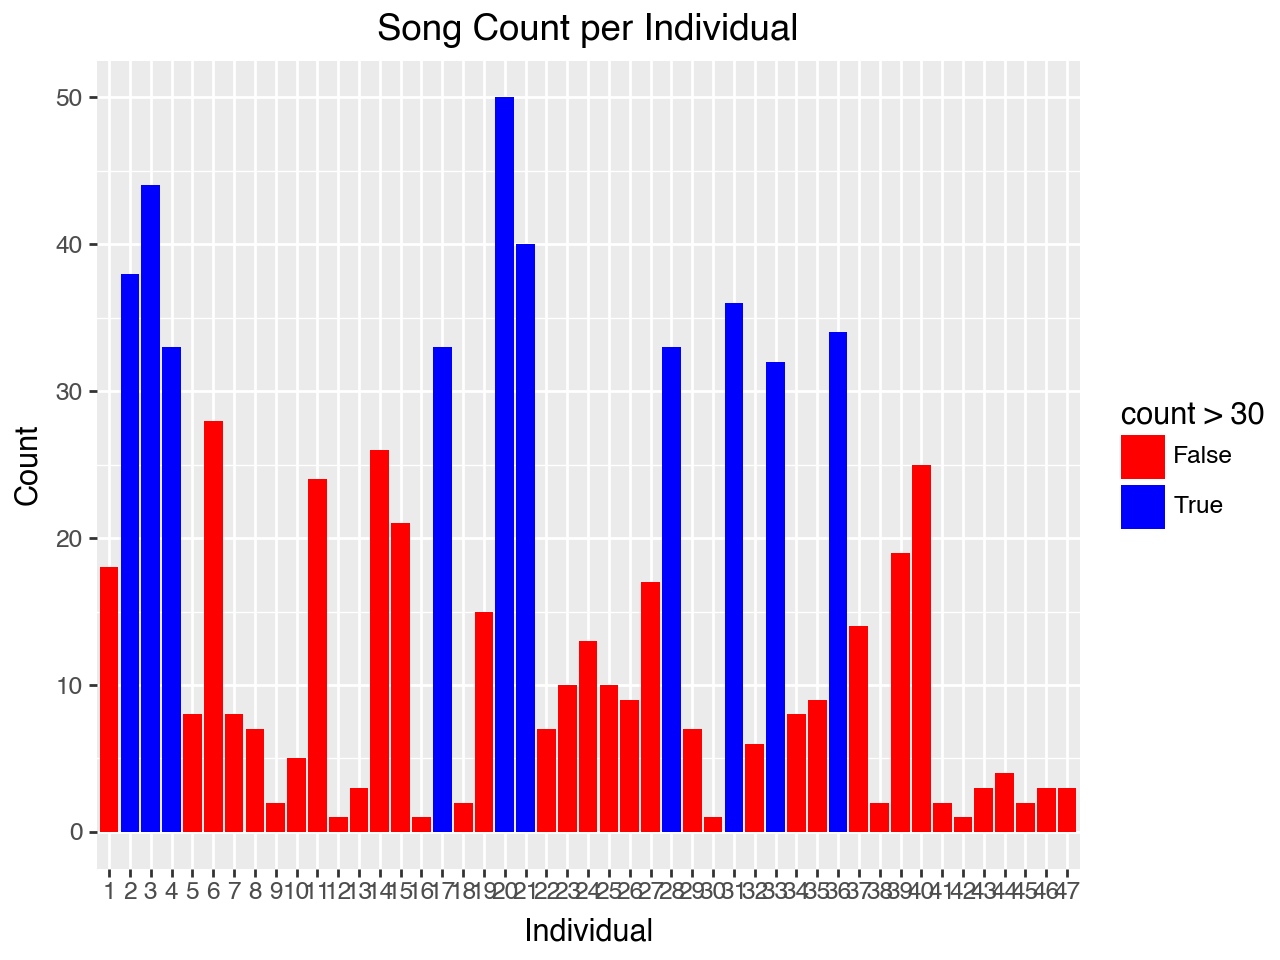

In [47]:
# add a new column individual so it does not conflict with python
subst_loaded_events_df['individual'] = subst_loaded_events_df['class']

# .value_counts() creates a lookup table, (individual: counts) for all individuals
# .map() takes that lookup table and assigns it to those individuals using 'individual' as the key
# This new column 'count' is assigned with that counts for each individual

subst_loaded_events_df['count'] = subst_loaded_events_df['individual'].map(
    subst_loaded_events_df['individual'].value_counts()
)

# Creates a ggplot object 
(
    ggplot(subst_loaded_events_df, aes(x='factor(individual)', fill='count > 30'))
    + geom_bar()
    + scale_fill_manual(
        values={True: 'blue', False: 'red'}
    )
    + labs(
        title='Song Count per Individual',
        x='Individual',
        y='Count'
    )
)